# 06_model_validation_and_feature_ablation

This notebook runs the two missing experiment groups: (1) five-fold rolling-origin time-series cross-validation on the 70% Philippine training partition, reporting mean and standard deviation across folds; and (2) input-feature ablation comparing both inputs, pH-only input, and temperature-only input while predicting both targets.

For transfer-learning ablation with one input feature, the corresponding row of the pretrained LSTM input-weight matrix is retained. This is a controlled adaptation of the pretrained input layer, not evidence that the source model was originally trained on one feature.


In [8]:
import os
os.environ["KERAS_BACKEND"] = "torch"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import Sequential
from keras.layers import Input, LSTM, Dropout, Dense
from keras.callbacks import EarlyStopping
from keras.models import load_model
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_SEED = 42
SEQ_LEN = 6
BATCH_SIZE = 8
MAX_EPOCHS = 100
PATIENCE = 5
TARGETS = ["water_pH", "water_temp"]

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p.resolve() for p in candidates if (p / "data" / "PH_data.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find data/PH_data.csv. Save this notebook in the project notebooks folder.")
DATA_PATH = ROOT / "data" / "PH_data.csv"
SOURCE_PATH = ROOT / "models" / "source_final.keras"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
if not SOURCE_PATH.exists():
    raise FileNotFoundError(f"Missing source model: {SOURCE_PATH}")

raw = pd.read_csv(DATA_PATH)
df = raw.rename(columns={"Date & Time":"created_date", "pH":"water_pH", "Water Temp (°C)":"water_temp"}).copy()
df["created_date"] = pd.to_datetime(df["created_date"])
df = df.sort_values("created_date").reset_index(drop=True)
train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)
train_df = df.iloc[:train_end].reset_index(drop=True)
val_df = df.iloc[train_end:val_end].reset_index(drop=True)
test_df = df.iloc[val_end:].reset_index(drop=True)
source_model = load_model(SOURCE_PATH)
source_lstm = next(layer for layer in source_model.layers if isinstance(layer, LSTM))
source_weights = source_lstm.get_weights()
print("Project:", ROOT)
print("Rows train/validation/test:", len(train_df), len(val_df), len(test_df))
print("Source model:", source_model.input_shape, "->", source_model.output_shape)


Project: C:\Users\Admin\Datas\PondPredict
Rows train/validation/test: 201 43 44
Source model: (None, 6, 2) -> (None, 2)


## A. Five-fold rolling-origin time-series cross-validation

The folds use only the 70% training partition. `TimeSeriesSplit` preserves chronology and uses five evaluation blocks of 20 observations. An inner tail of each outer training period is used for early stopping; the later evaluation block is not used to select epochs. Fold evaluation sequences use preceding observations as context.


In [3]:
def make_range_sequences(scaled, start, end, feature_indices, seq_len=SEQ_LEN):
    X, y = [], []
    for i in range(max(seq_len, start), end):
        X.append(scaled[i-seq_len:i, feature_indices])
        y.append(scaled[i, :])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

def build_and_fit(kind, feature_indices, Xtr, ytr, Xva, yva, seed):
    keras.utils.set_random_seed(seed)
    n_features = len(feature_indices)
    lstm_name = "transfer_lstm" if kind == "transfer" else "baseline_lstm"
    model = Sequential([Input(shape=(SEQ_LEN, n_features)), LSTM(16, name=lstm_name), Dropout(0.20), Dense(2)])
    if kind == "transfer":
        kernel, recurrent, bias = source_weights
        model.get_layer(lstm_name).set_weights([kernel[np.asarray(feature_indices), :], recurrent, bias])
        model.get_layer(lstm_name).trainable = False
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.005), loss="mse", metrics=["mae"])
    stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    hist1 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=[stop], verbose=0)
    epochs_used = len(hist1.history["loss"])
    if kind == "transfer":
        model.get_layer(lstm_name).trainable = True
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005), loss="mse", metrics=["mae"])
        stop2 = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        hist2 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=[stop2], verbose=0)
        epochs_used += len(hist2.history["loss"])
    return model, epochs_used

def metrics_original_units(model, X, y_scaled, scaler):
    pred_scaled = model.predict(X, verbose=0)
    y_true = scaler.inverse_transform(y_scaled)
    y_pred = scaler.inverse_transform(pred_scaled)
    rows = []
    for j, target in enumerate(TARGETS):
        rows.append({"Target":target, "MAE":mean_absolute_error(y_true[:,j], y_pred[:,j]),
                     "RMSE":np.sqrt(mean_squared_error(y_true[:,j], y_pred[:,j])), "R2":r2_score(y_true[:,j], y_pred[:,j])})
    return rows

cv_rows = []
cv = TimeSeriesSplit(n_splits=5, test_size=20)
for fold, (tr_idx, ev_idx) in enumerate(cv.split(train_df), start=1):
    outer_train = train_df.iloc[tr_idx].reset_index(drop=True)
    outer_eval = train_df.iloc[ev_idx].reset_index(drop=True)
    combined = pd.concat([outer_train, outer_eval], ignore_index=True)
    inner = int(len(outer_train) * 0.85)
    scaler = MinMaxScaler().fit(outer_train.iloc[:inner][TARGETS])
    scaled = scaler.transform(combined[TARGETS])
    Xtr, ytr = make_range_sequences(scaled, SEQ_LEN, inner, [0,1])
    Xva, yva = make_range_sequences(scaled, inner, len(outer_train), [0,1])
    Xev, yev = make_range_sequences(scaled, len(outer_train), len(combined), [0,1])
    if min(len(Xtr), len(Xva), len(Xev)) == 0:
        raise ValueError(f"Empty sequence set in fold {fold}; inspect the split configuration.")
    for kind in ["baseline", "transfer"]:
        model, epochs_used = build_and_fit(kind, [0,1], Xtr, ytr, Xva, yva, RANDOM_SEED + fold)
        for result in metrics_original_units(model, Xev, yev, scaler):
            cv_rows.append({"Fold":fold, "Model":"Philippine-only LSTM" if kind == "baseline" else "Transfer-learning LSTM",
                            "Target":result["Target"], "MAE":result["MAE"], "RMSE":result["RMSE"], "R2":result["R2"],
                            "Epochs":epochs_used, "Outer_train_rows":len(outer_train), "Fold_rows":len(outer_eval), "Fold_sequences":len(Xev)})
        print(f"Completed fold {fold}: {kind}")

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(RESULTS / "timeseries_cv_fold_results.csv", index=False)
cv_summary = cv_results.groupby(["Model","Target"])[["MAE","RMSE","R2"]].agg(["mean","std"]).reset_index()
cv_summary.columns = ["_".join([str(x) for x in c if str(x)]) if isinstance(c, tuple) else c for c in cv_summary.columns]
cv_summary.to_csv(RESULTS / "timeseries_cv_mean_std.csv", index=False)
display(cv_results)
display(cv_summary)


Completed fold 1: baseline
Completed fold 1: transfer
Completed fold 2: baseline
Completed fold 2: transfer
Completed fold 3: baseline
Completed fold 3: transfer
Completed fold 4: baseline
Completed fold 4: transfer
Completed fold 5: baseline
Completed fold 5: transfer


,Fold,Model,Target,MAE,RMSE,R2,Epochs,Outer_train_rows,Fold_rows,Fold_sequences
0,1,Philippine-only LSTM,water_pH,0.030890,0.037237,0.743172,14,101,20,20
1,1,Philippine-only LSTM,water_temp,0.327611,0.370814,0.948161,14,101,20,20
2,1,Transfer-learning LSTM,water_pH,0.012109,0.013815,0.964651,35,101,20,20
3,1,Transfer-learning LSTM,water_temp,0.133346,0.179771,0.987816,35,101,20,20
4,2,Philippine-only LSTM,water_pH,0.019562,0.023446,0.939652,22,121,20,20
5,2,Philippine-only LSTM,water_temp,0.231995,0.307680,0.973215,22,121,20,20
6,2,Transfer-learning LSTM,water_pH,0.013803,0.016914,0.968591,71,121,20,20
7,2,Transfer-learning LSTM,water_temp,0.169057,0.228639,0.985209,71,121,20,20
8,3,Philippine-only LSTM,water_pH,0.016441,0.019125,0.948181,25,141,20,20
9,3,Philippine-only LSTM,water_temp,0.166058,0.199061,0.986194,25,141,20,20


,Model,Target,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,Philippine-only LSTM,water_pH,0.020442,0.007719,0.024332,0.009277,0.899472,0.092758
1,Philippine-only LSTM,water_temp,0.208203,0.079496,0.251132,0.092563,0.975179,0.017725
2,Transfer-learning LSTM,water_pH,0.013178,0.000919,0.016010,0.001515,0.964189,0.004766
3,Transfer-learning LSTM,water_temp,0.149057,0.022475,0.191671,0.031989,0.987093,0.004076


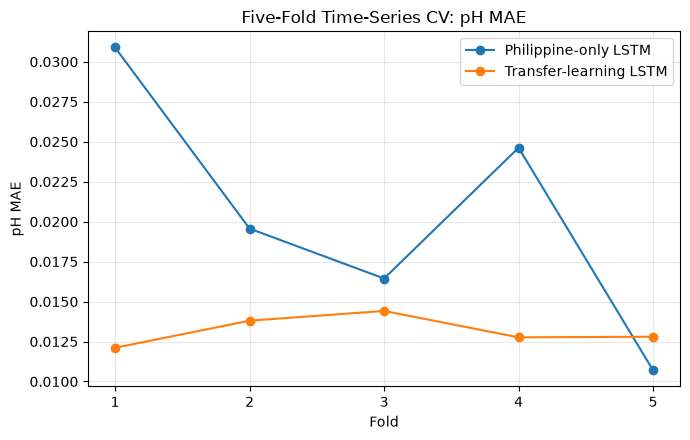

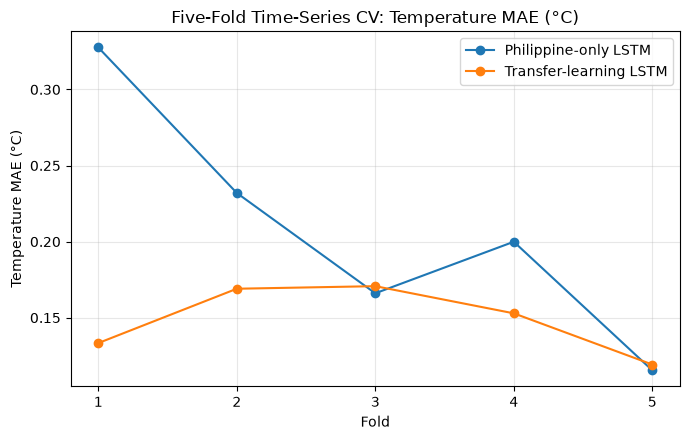

In [4]:
for target, filename, ylabel in [("water_pH", "timeseries_cv_pH_MAE.png", "pH MAE"), ("water_temp", "timeseries_cv_temperature_MAE.png", "Temperature MAE (°C)")]:
    subset = cv_results[cv_results["Target"] == target]
    fig, ax = plt.subplots(figsize=(7,4.5))
    for name, group in subset.groupby("Model"):
        ax.plot(group["Fold"], group["MAE"], marker="o", label=name)
    ax.set_title(f"Five-Fold Time-Series CV: {ylabel}")
    ax.set_xlabel("Fold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(subset["Fold"].unique()))
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=300, bbox_inches="tight")
    plt.show()


## B. Input-feature ablation

The models are retrained with (1) both inputs, (2) pH only, and (3) temperature only. Both output targets remain pH and temperature. The scaler is fit on the training partition only, and validation/test sequences are formed within their own partitions to match the existing experiment protocol. The held-out test set is used only for final ablation evaluation.


In [5]:
def make_partition_sequences(scaled_partition, feature_indices):
    X, y = [], []
    for i in range(SEQ_LEN, len(scaled_partition)):
        X.append(scaled_partition[i-SEQ_LEN:i, feature_indices])
        y.append(scaled_partition[i, :])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

scaler_ab = MinMaxScaler().fit(train_df[TARGETS])
train_scaled = scaler_ab.transform(train_df[TARGETS])
val_scaled = scaler_ab.transform(val_df[TARGETS])
test_scaled = scaler_ab.transform(test_df[TARGETS])
feature_sets = {"Both (pH + temperature)":[0,1], "pH only":[0], "Temperature only":[1]}
ablation_rows = []
for feature_label, indices in feature_sets.items():
    Xtr, ytr = make_partition_sequences(train_scaled, indices)
    Xva, yva = make_partition_sequences(val_scaled, indices)
    Xte, yte = make_partition_sequences(test_scaled, indices)
    for kind in ["baseline", "transfer"]:
        model, epochs_used = build_and_fit(kind, indices, Xtr, ytr, Xva, yva, RANDOM_SEED)
        for result in metrics_original_units(model, Xte, yte, scaler_ab):
            ablation_rows.append({"Input_features":feature_label,
                "Model":"Philippine-only LSTM" if kind == "baseline" else "Transfer-learning LSTM",
                "Target":result["Target"], "MAE":result["MAE"], "RMSE":result["RMSE"], "R2":result["R2"],
                "Training_sequences":len(Xtr), "Validation_sequences":len(Xva), "Test_sequences":len(Xte), "Epochs":epochs_used})
        print(f"Completed ablation: {feature_label} | {kind}")

ablation = pd.DataFrame(ablation_rows)
full = ablation[ablation["Input_features"] == "Both (pH + temperature)"][["Model","Target","MAE"]].rename(columns={"MAE":"Both_features_MAE"})
ablation = ablation.merge(full, on=["Model","Target"], how="left")
ablation["MAE_change_vs_both"] = ablation["MAE"] - ablation["Both_features_MAE"]
ablation.to_csv(RESULTS / "feature_ablation_with_delta.csv", index=False)
display(ablation)


Completed ablation: Both (pH + temperature) | baseline
Completed ablation: Both (pH + temperature) | transfer
Completed ablation: pH only | baseline
Completed ablation: pH only | transfer
Completed ablation: Temperature only | baseline
Completed ablation: Temperature only | transfer


,Input_features,Model,Target,MAE,RMSE,R2,Training_sequences,Validation_sequences,Test_sequences,Epochs,Both_features_MAE,MAE_change_vs_both
0,Both (pH + temperature),Philippine-only LSTM,water_pH,0.022774,0.028628,0.810680,195,37,38,14,0.022774,0.000000
1,Both (pH + temperature),Philippine-only LSTM,water_temp,0.187075,0.231706,0.981441,195,37,38,14,0.187075,0.000000
2,Both (pH + temperature),Transfer-learning LSTM,water_pH,0.031911,0.036077,0.699337,195,37,38,13,0.031911,0.000000
3,Both (pH + temperature),Transfer-learning LSTM,water_temp,0.233399,0.285074,0.971907,195,37,38,13,0.233399,0.000000
4,pH only,Philippine-only LSTM,water_pH,0.021639,0.025628,0.848272,195,37,38,14,0.022774,-0.001135
5,pH only,Philippine-only LSTM,water_temp,0.882386,1.056637,0.614053,195,37,38,14,0.187075,0.695310
6,pH only,Transfer-learning LSTM,water_pH,0.022640,0.026862,0.833310,195,37,38,70,0.031911,-0.009271
7,pH only,Transfer-learning LSTM,water_temp,0.791691,1.039224,0.626668,195,37,38,70,0.233399,0.558293
8,Temperature only,Philippine-only LSTM,water_pH,0.051703,0.059745,0.175437,195,37,38,18,0.022774,0.028930
9,Temperature only,Philippine-only LSTM,water_temp,0.191842,0.238997,0.980255,195,37,38,18,0.187075,0.004766


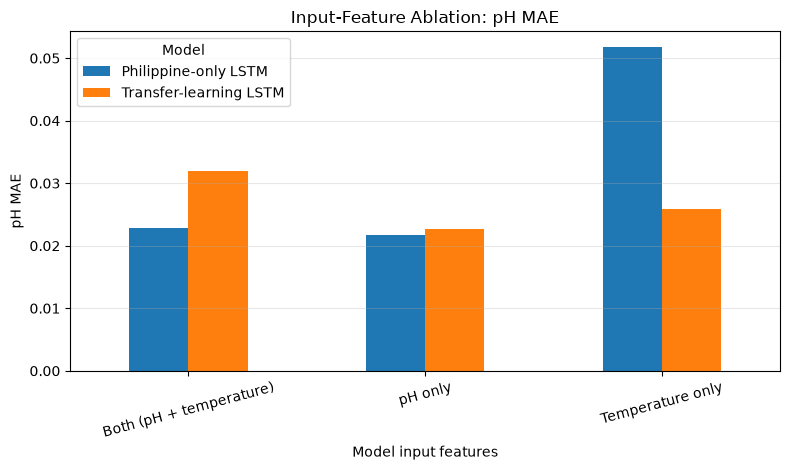

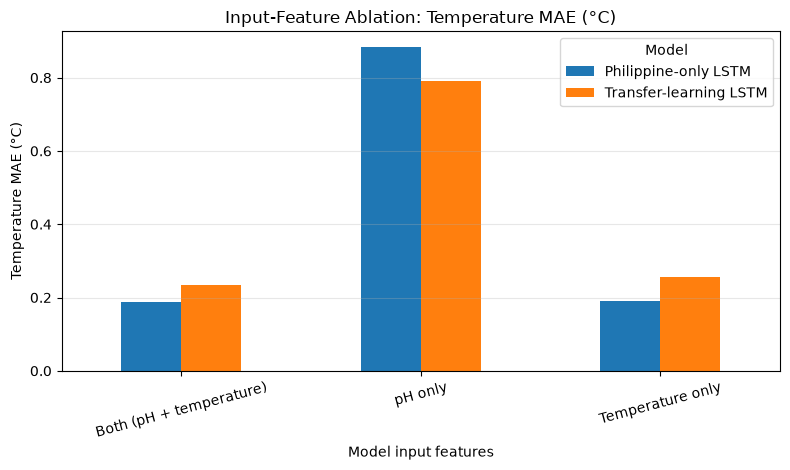

Saved CV and feature-ablation outputs to: C:\Users\Admin\Datas\PondPredict\results


In [6]:
for target, filename, ylabel in [("water_pH", "feature_ablation_pH_MAE.png", "pH MAE"), ("water_temp", "feature_ablation_temperature_MAE.png", "Temperature MAE (°C)")]:
    subset = ablation[ablation["Target"] == target]
    pivot = subset.pivot(index="Input_features", columns="Model", values="MAE")
    pivot = pivot.reindex(["Both (pH + temperature)", "pH only", "Temperature only"])
    fig, ax = plt.subplots(figsize=(8,4.8))
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(f"Input-Feature Ablation: {ylabel}")
    ax.set_xlabel("Model input features")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Model")
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=300, bbox_inches="tight")
    plt.show()

print("Saved CV and feature-ablation outputs to:", RESULTS)


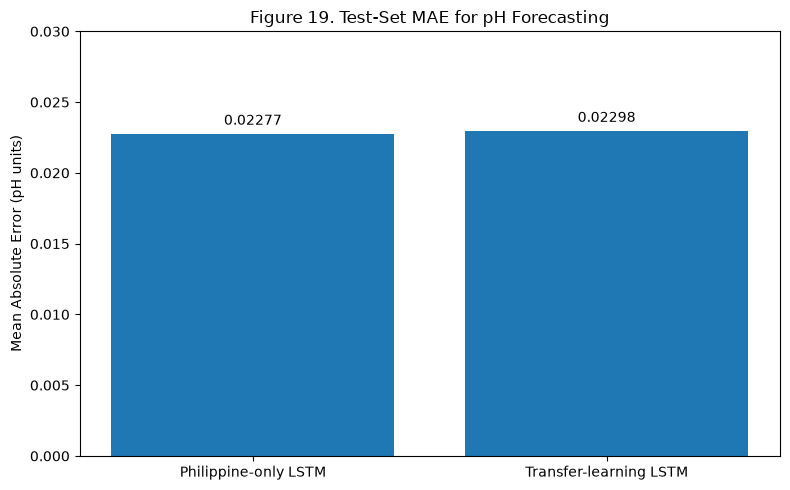

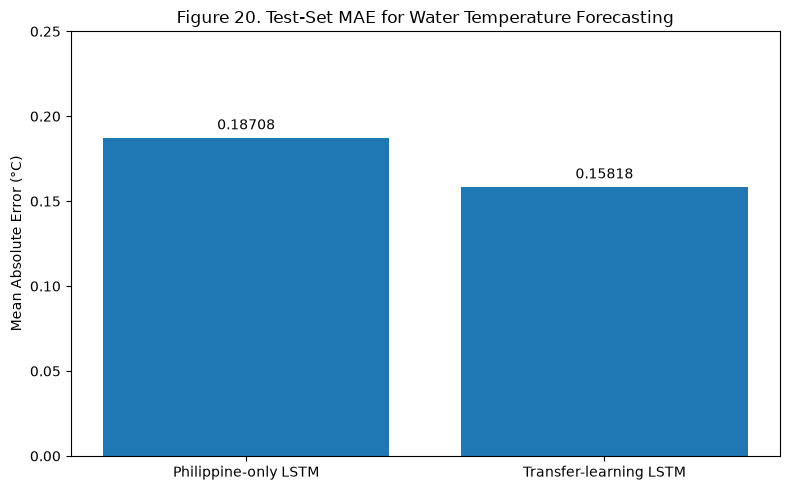

Both figures have been saved.


In [10]:

import matplotlib.pyplot as plt

models = ["Philippine-only LSTM", "Transfer-learning LSTM"]

# Figure 19: pH forecasting
ph_mae = [0.0227735459, 0.0229779133]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, ph_mae)
plt.title("Figure 19. Test-Set MAE for pH Forecasting")
plt.ylabel("Mean Absolute Error (pH units)")
plt.ylim(0, 0.03)
plt.bar_label(bars, fmt="%.5f", padding=4)
plt.tight_layout()
plt.savefig("Figure_19_pH_MAE.png", dpi=300)
plt.show()
plt.close()

# Figure 20: water temperature forecasting
temp_mae = [0.1870752736, 0.1581814716]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, temp_mae)
plt.title("Figure 20. Test-Set MAE for Water Temperature Forecasting")
plt.ylabel("Mean Absolute Error (°C)")
plt.ylim(0, 0.25)
plt.bar_label(bars, fmt="%.5f", padding=4)
plt.tight_layout()
plt.savefig("Figure_20_Temperature_MAE.png", dpi=300)
plt.show()
plt.close()

print("Both figures have been saved.")


## Chapter 4 reporting

Use `results/timeseries_cv_mean_std.csv` for the mean and standard deviation across five time-ordered folds, and `results/feature_ablation_with_delta.csv` for the ablation table. Insert the generated PNGs from `results/`. Report CV results separately from the final held-out test metrics. Describe feature effects as specific to this dataset, split, and model configuration; do not treat them as universal physical importance.
